Gruppe: Sven van Tongeren, Patrick Heß, Sebastian Straßner, Daniel Daub

In [20]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

In [21]:
df = pd.read_csv("data.csv")
df["observation_date"] = pd.to_datetime(df["observation_date"])
df = df.rename(columns={"observation_date": "date", "IPG2211A2N": "value"})
df = df.set_index("date").sort_index()
df

,value
date,
1939-01-01,3.3336
1939-02-01,3.3591
1939-03-01,3.4354
1939-04-01,3.4608
1939-05-01,3.4608
...,...
2025-11-01,101.4705
2025-12-01,121.2860
2026-01-01,130.3652


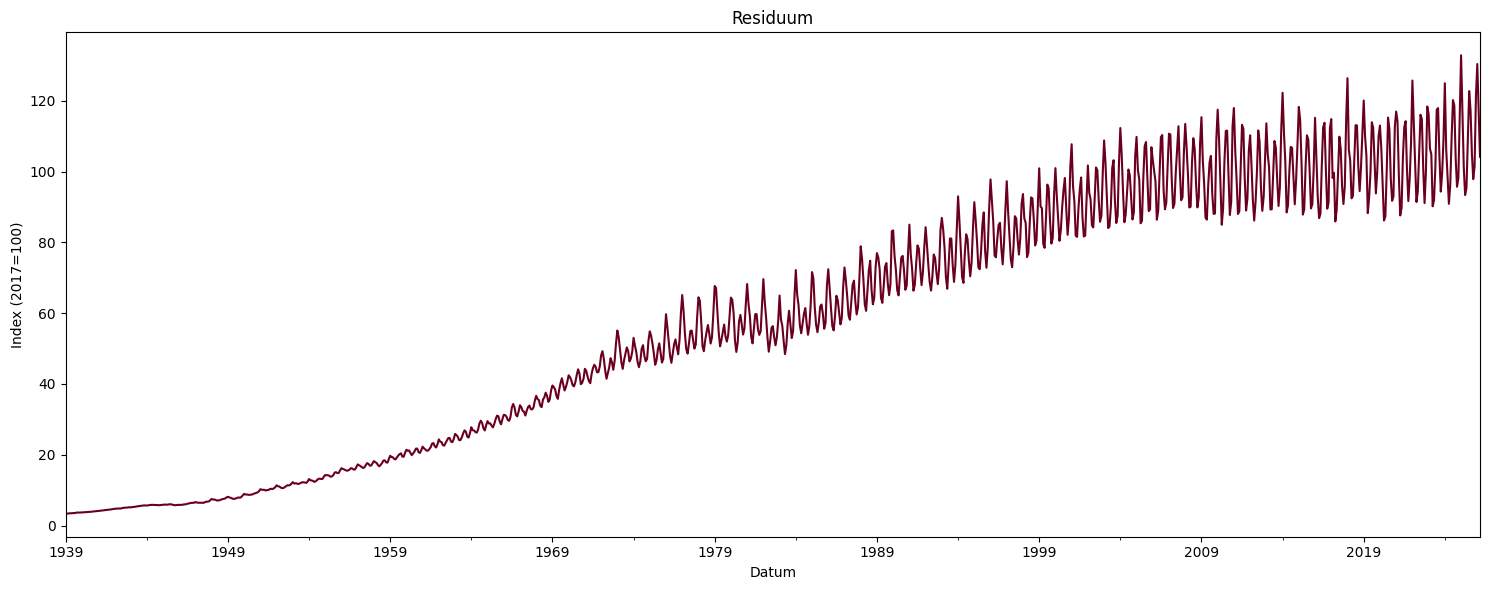

In [22]:
series = df["value"].sort_index()

_, ax = plt.subplots(figsize=(15, 6))
series.plot(ax=ax, color="#6B001E")
ax.set(
    title="Residuum",
    xlabel="Datum",
    ylabel="Index (2017=100)",
)
ax.margins(x=0)

plt.tight_layout()
plt.show()

## Saisonalität

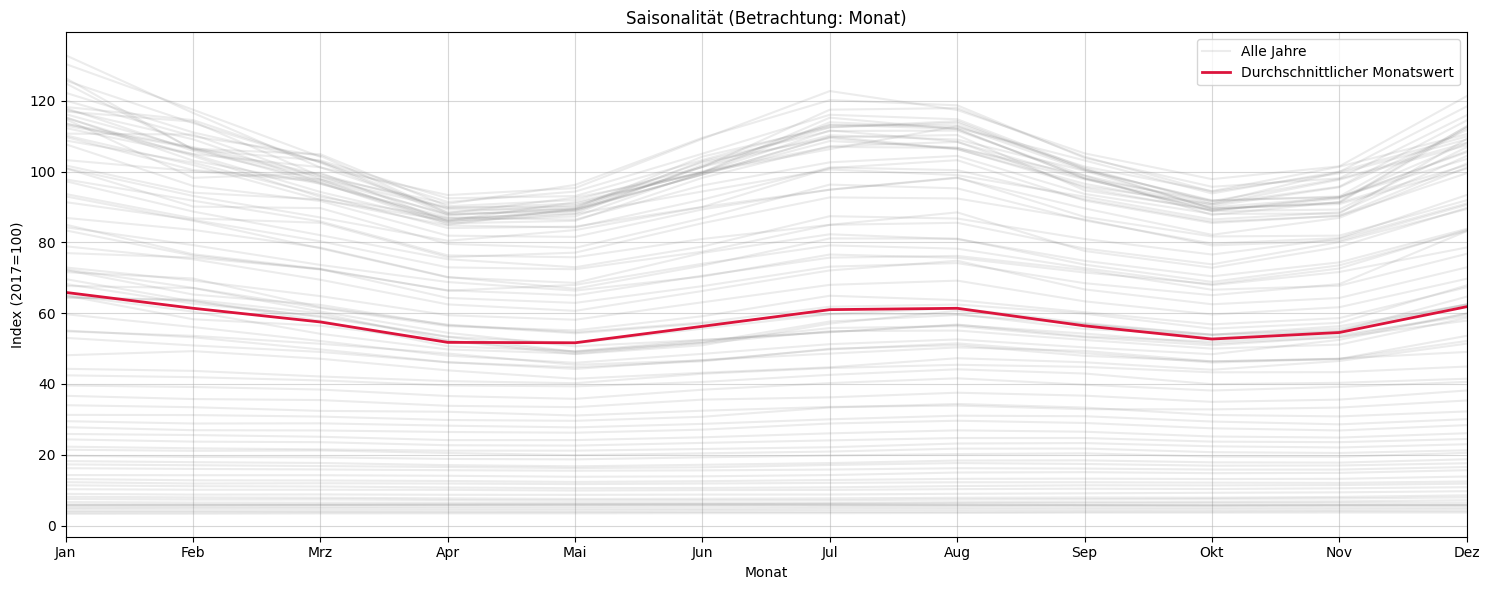

In [23]:
def analyse_seasonality(df: pd.DataFrame, col: str = "value", title: str = "") -> None:
    df = df.copy()
    df["month"] = df.index.month  # Fokus auf ein Jahr setzen

    # Der Mittelwert aller Monate über alle Jahre
    seasonal = df.groupby("month")[col].mean()

    _, ax = plt.subplots(figsize=(15, 6))

    # Verbrauch aller Jahre zur Veranschaulichung
    df["pivot_year"] = df.index.year
    pivot_data = df.pivot_table(index="month", columns="pivot_year", values=col)

    lines = ax.plot(pivot_data, color="gray", alpha=0.15)
    if lines:
        lines[0].set_label("Alle Jahre")

    seasonal.plot(ax=ax, color="crimson", linewidth=2, label="Durchschnittlicher Monatswert")

    ax.set(
        title=title,
        xlabel="Monat",
        ylabel="Index (2017=100)",
    )
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(["Jan", "Feb", "Mrz", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"])
    ax.grid(axis="both", alpha=0.5)
    ax.margins(x=0)
    ax.legend()
    plt.tight_layout()
    plt.show()


analyse_seasonality(df, col="value", title="Saisonalität (Betrachtung: Monat)")

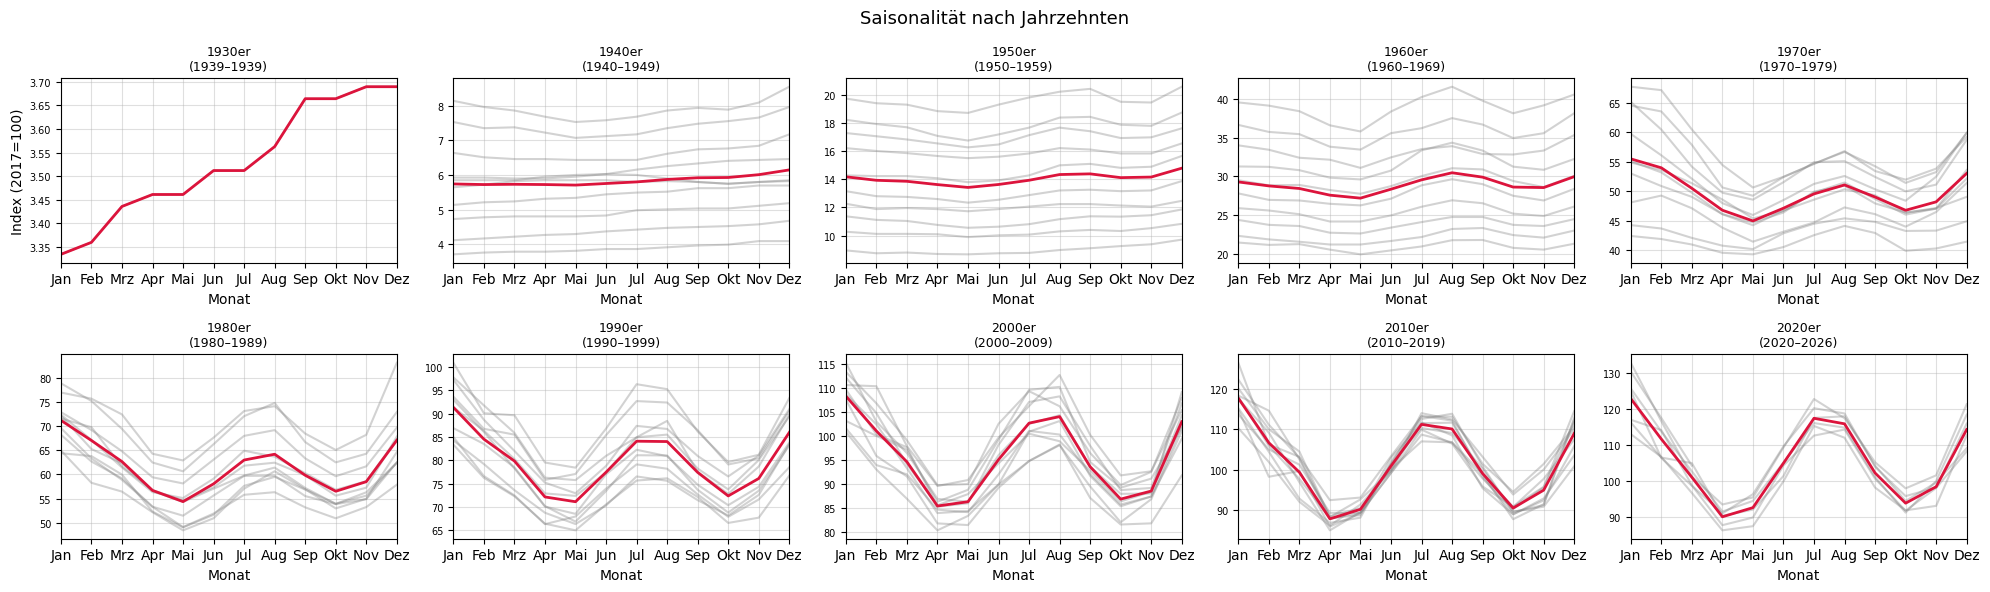

In [24]:
def analyse_seasonality_by_decade(df: pd.DataFrame, col: str = "value", title: str = "") -> None:
    df = df.copy()
    df["month"] = df.index.month
    df["year"] = df.index.year
    df["decade"] = (df["year"] // 10) * 10

    decades = sorted(df["decade"].unique())

    fig, axes = plt.subplots(2, 5, figsize=(20, 6), sharey=False)
    axes = axes.flatten()

    for ax, decade in zip(axes, decades):
        decade_df = df[df["decade"] == decade]
        pivot_data = decade_df.pivot_table(index="month", columns="year", values=col)
        seasonal = decade_df.groupby("month")[col].mean()

        lines = ax.plot(pivot_data, color="gray", alpha=0.35)
        if lines:
            lines[0].set_label("Einzelne Jahre")
        seasonal.plot(ax=ax, color="crimson", linewidth=2, label="Dekadenmittel")

        year_min = decade_df["year"].min()
        year_max = decade_df["year"].max()
        ax.set_title(f"{decade}er\n({year_min}–{year_max})", fontsize=9)
        ax.set_xlabel("Monat")
        ax.set_xticks(range(1, 13))
        ax.set_xticklabels(["Jan", "Feb", "Mrz", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"])
        ax.grid(axis="both", alpha=0.4)
        ax.margins(x=0)
        ax.tick_params(axis="y", labelsize=7)

    axes[0].set_ylabel("Index (2017=100)")
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()


analyse_seasonality_by_decade(df, col="value", title="Saisonalität nach Jahrzehnten")

<font color="orange">
Man sieht deutlich, dass wir eine multiplikative Seasionalität haben, da diese mit der Zeit steigt.
</font>

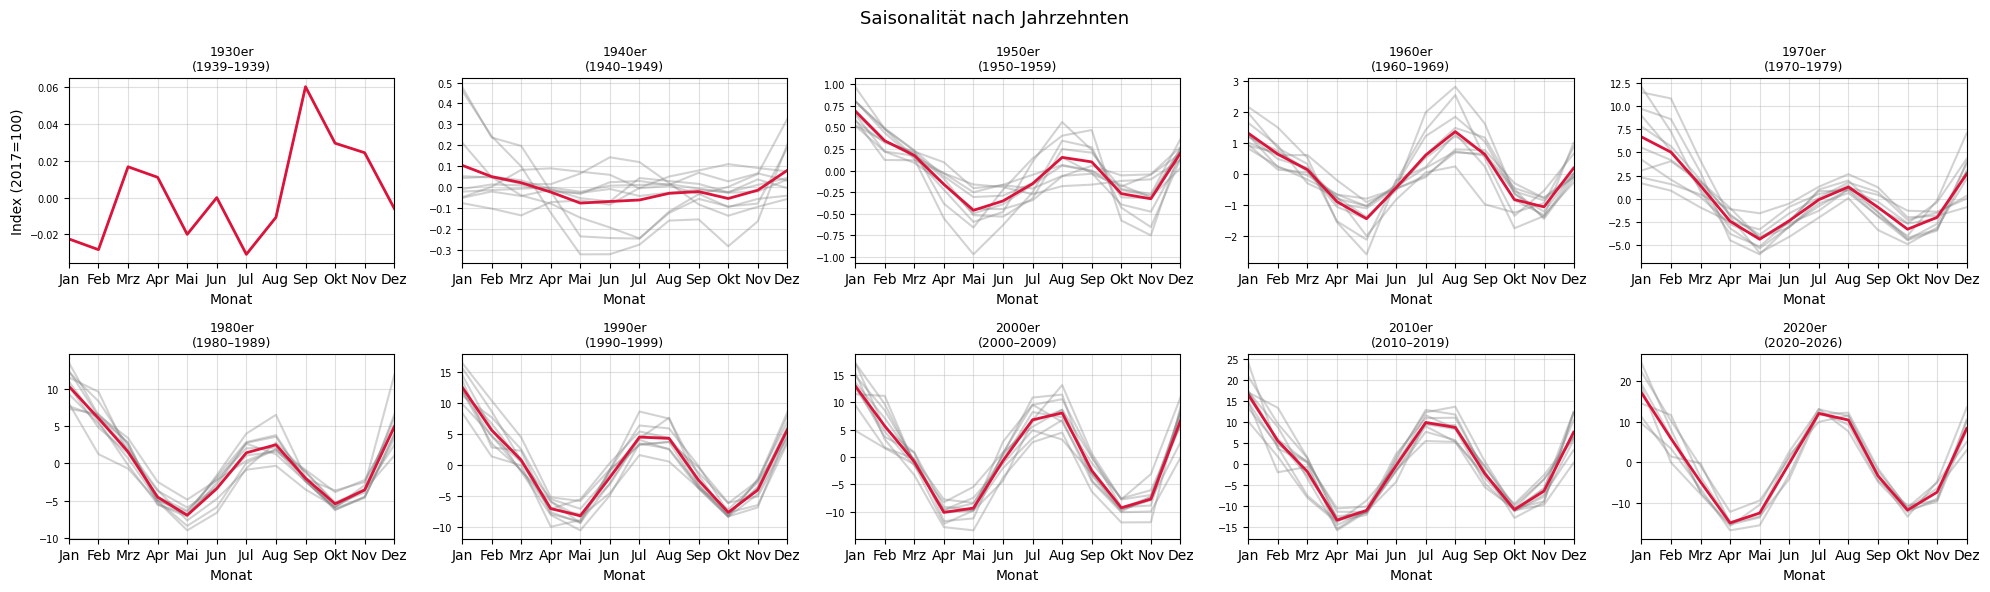

In [25]:
from statsmodels.tsa.seasonal import STL

decomposition = STL(df["value"], period=12, robust=True)
decomposition = decomposition.fit()

df["trend"] = decomposition.trend
df["value_detrended"] = df["value"] - df["trend"]
analyse_seasonality_by_decade(df, col="value_detrended", title="Saisonalität nach Jahrzehnten")

<font color="orange">
Trendbereinigt.
</font>

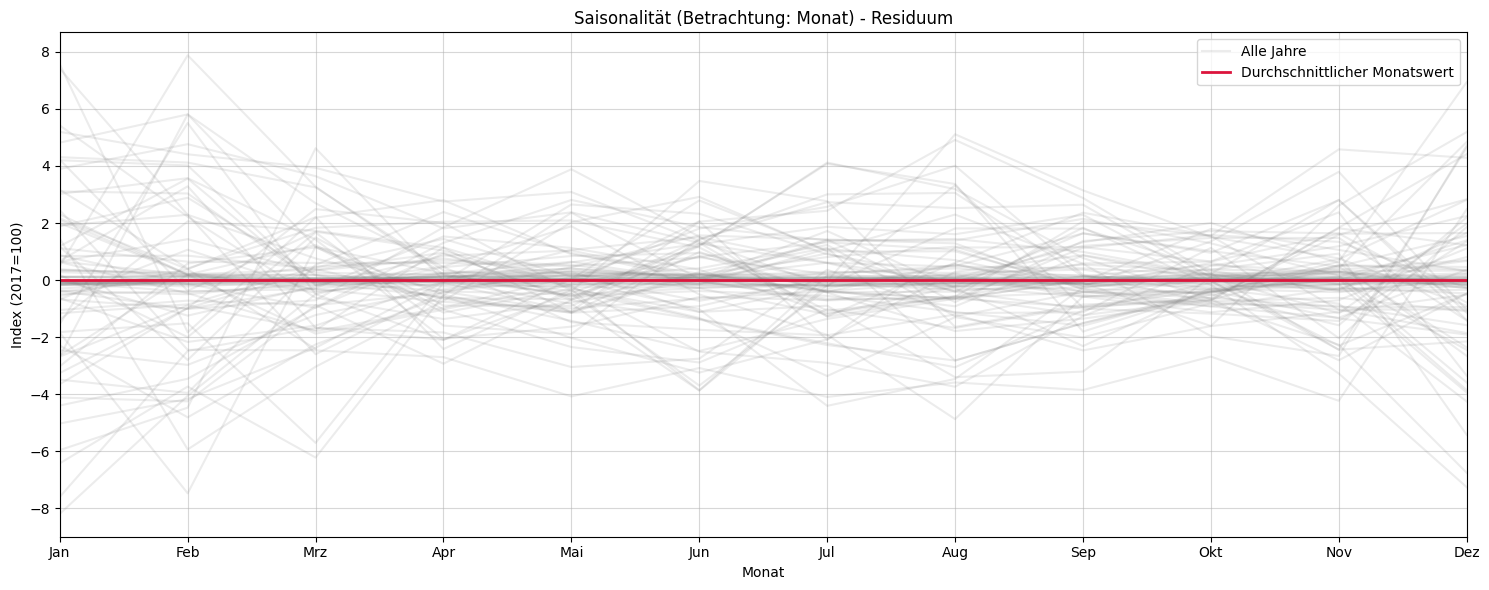

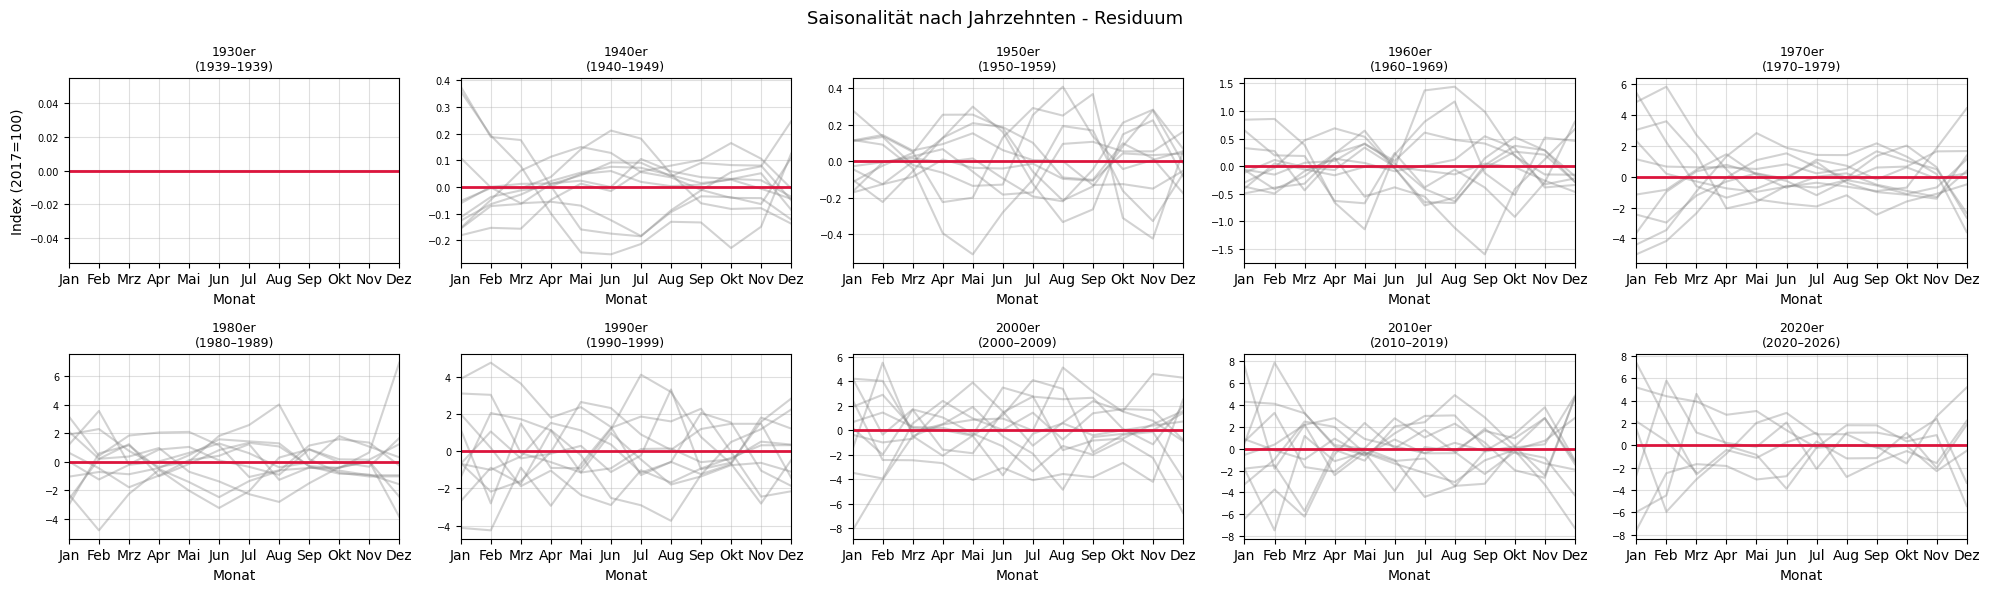

In [26]:
# Hilfsspalten
df["month"] = df.index.month
df["decade"] = (df.index.year // 10) * 10

# Saisonkomponente: Mittelwert je Dekade und Monat (auf der trendbereinigten Reihe)
df["seasonal_decade"] = df.groupby(["decade", "month"])["value_detrended"].transform("mean")

# Residuum
df["residuum"] = df["value_detrended"] - df["seasonal_decade"]

# Hilfsspalten entfernen
df = df.drop(columns=["month", "decade"])
analyse_seasonality(df, col="residuum", title="Saisonalität (Betrachtung: Monat) - Residuum")
analyse_seasonality_by_decade(df, col="residuum", title="Saisonalität nach Jahrzehnten - Residuum")

<font color="orange">
Mittelwert der Saisonalitäten bei dem Residuum der Zeitreihe ist gleich 0, die Zeitreihe wurde also vollständig bereinigt.
</font>

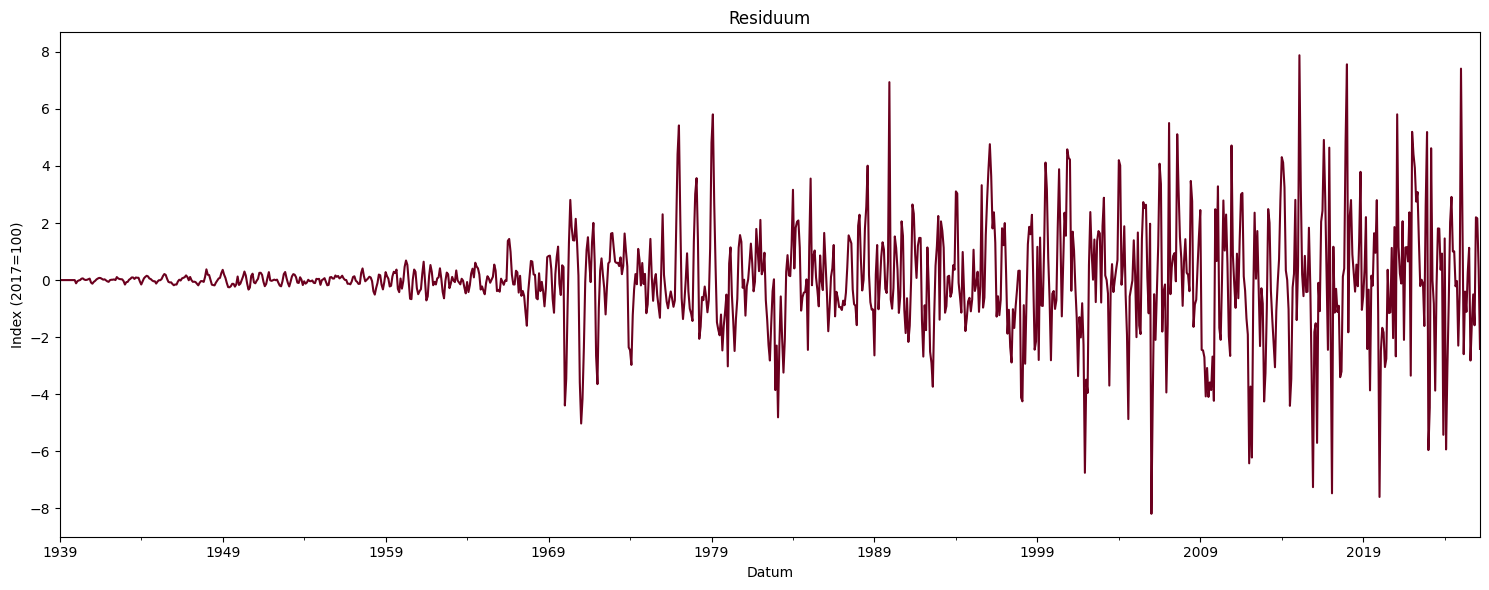

In [27]:
series = df["residuum"].sort_index()

_, ax = plt.subplots(figsize=(15, 6))
series.plot(ax=ax, color="#6B001E")
ax.set(
    title="Residuum",
    xlabel="Datum",
    ylabel="Index (2017=100)",
)
ax.margins(x=0)

plt.tight_layout()
plt.show()

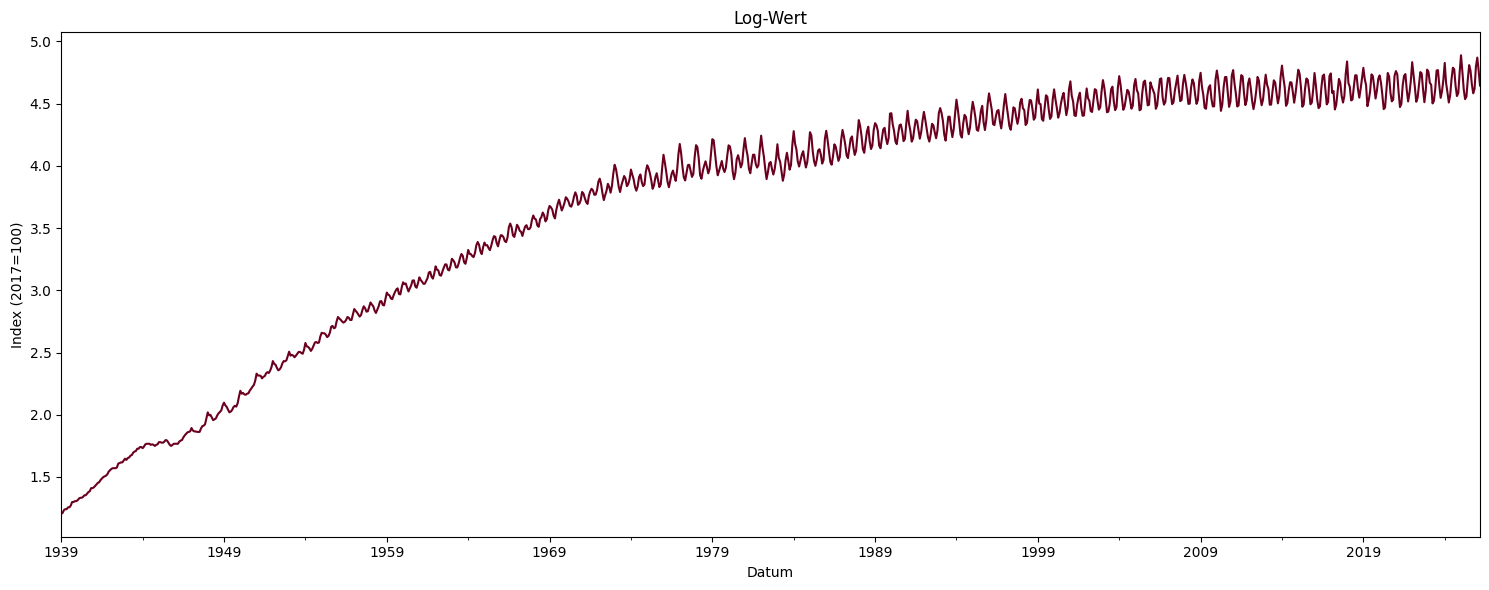

In [28]:
df["value_log"] = np.log(df["value"])
series = df["value_log"].sort_index()

_, ax = plt.subplots(figsize=(15, 6))
series.plot(ax=ax, color="#6B001E")
ax.set(
    title="Log-Wert",
    xlabel="Datum",
    ylabel="Index (2017=100)",
)
ax.margins(x=0)

plt.tight_layout()
plt.show()

<font color="orange">
Wir haben durch Recherche herausgefunden, dass sich für die Bereinigung multiplikativer Sasionalität sich der Logarithmus sehr gut eignet.
</font>

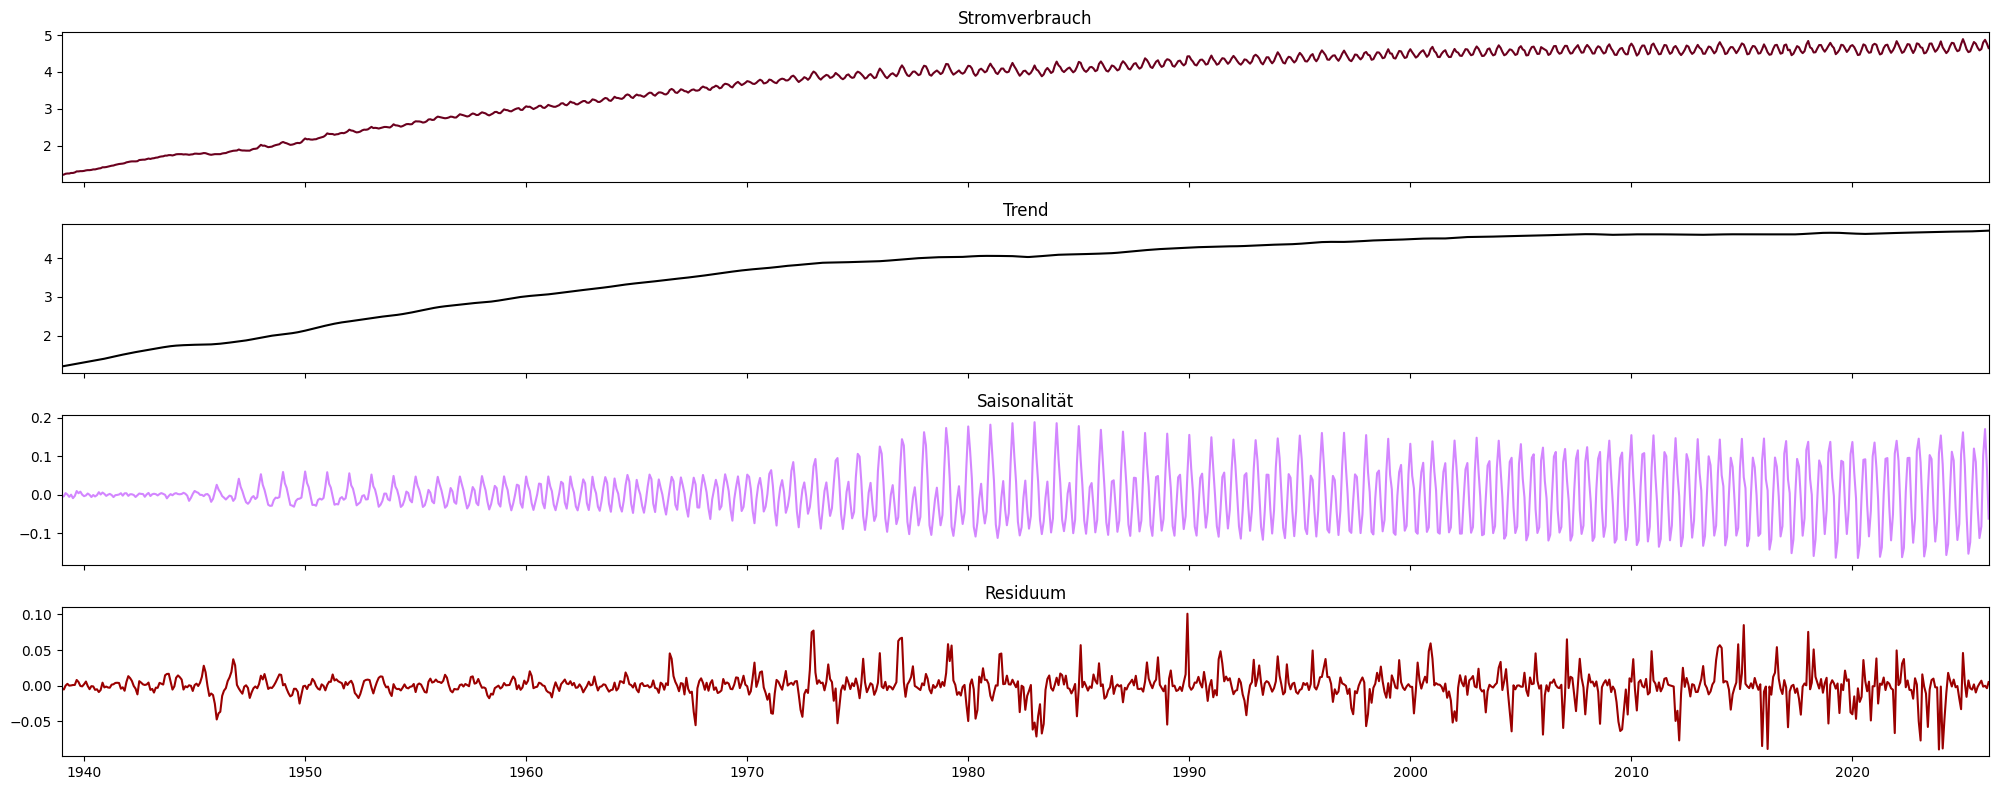

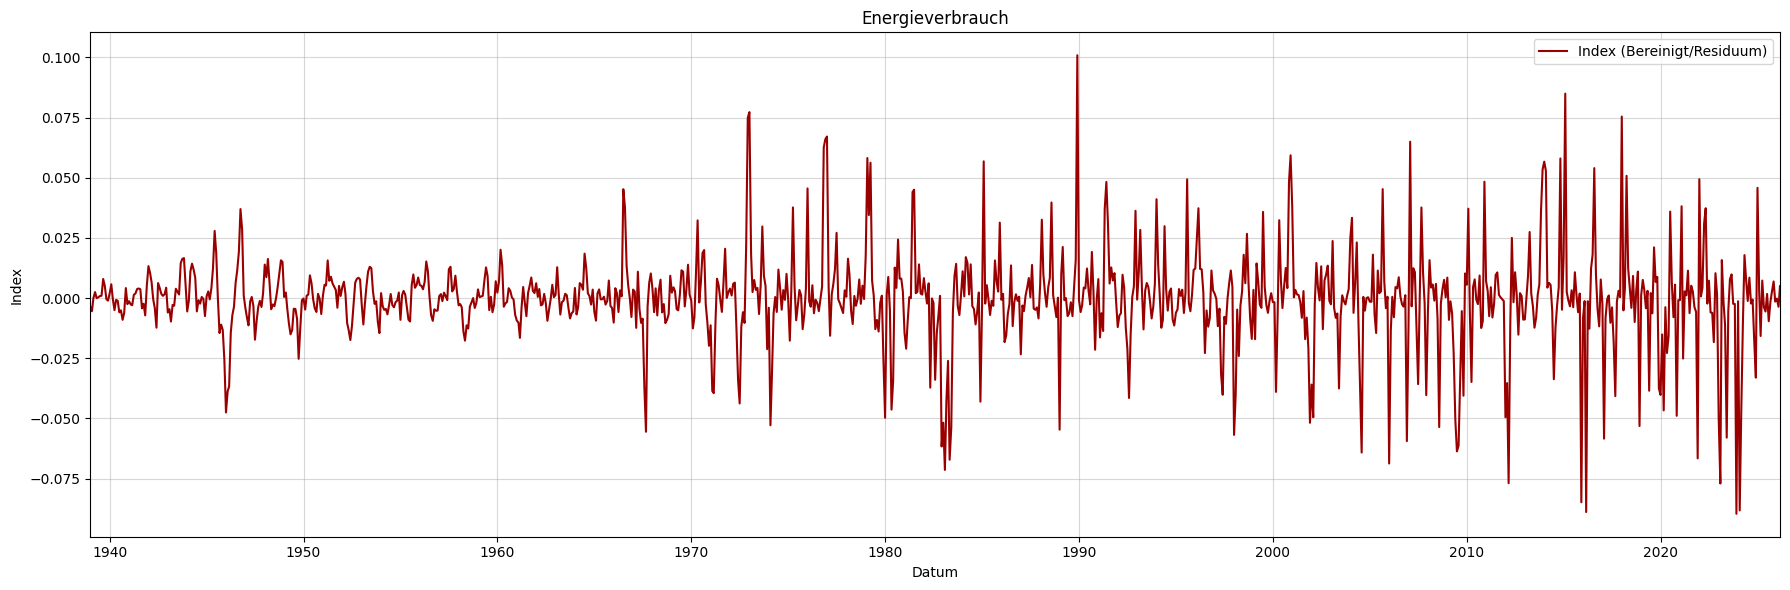

In [29]:
decomposition = STL(df["value_log"], period=12, robust=True)
decomposition = decomposition.fit()

_, ax = plt.subplots(4, 1, figsize=(20, 8), sharex=True)

ax[0].plot(df["value_log"], color="#6B001E")
ax[0].set_title("Stromverbrauch")

ax[1].plot(decomposition.trend, color="#000000FF")
ax[1].set_title("Trend")

ax[2].plot(decomposition.seasonal, color="#D386FF")
ax[2].set_title("Saisonalität")

ax[3].plot(decomposition.resid, color="#9B0000")
ax[3].set_title("Residuum")

plt.margins(x=0)
plt.tight_layout()
plt.show()

# Residuum der gesamten Zeitreihe
plt.figure(figsize=(18, 6))

plt.plot(df.index, decomposition.resid, color="#9B0000", label="Index (Bereinigt/Residuum)")

plt.title("Energieverbrauch")
plt.xlabel("Datum")
plt.ylabel("Index")
plt.grid(alpha=0.5)
plt.margins(x=0)
plt.legend()
plt.tight_layout()
plt.show()

df["log_trend"] = decomposition.trend
df["log_trendbereinigt"] = df["value_log"] - df["log_trend"]
df["log_saison"] = decomposition.seasonal
df["log_residuum"] = decomposition.resid

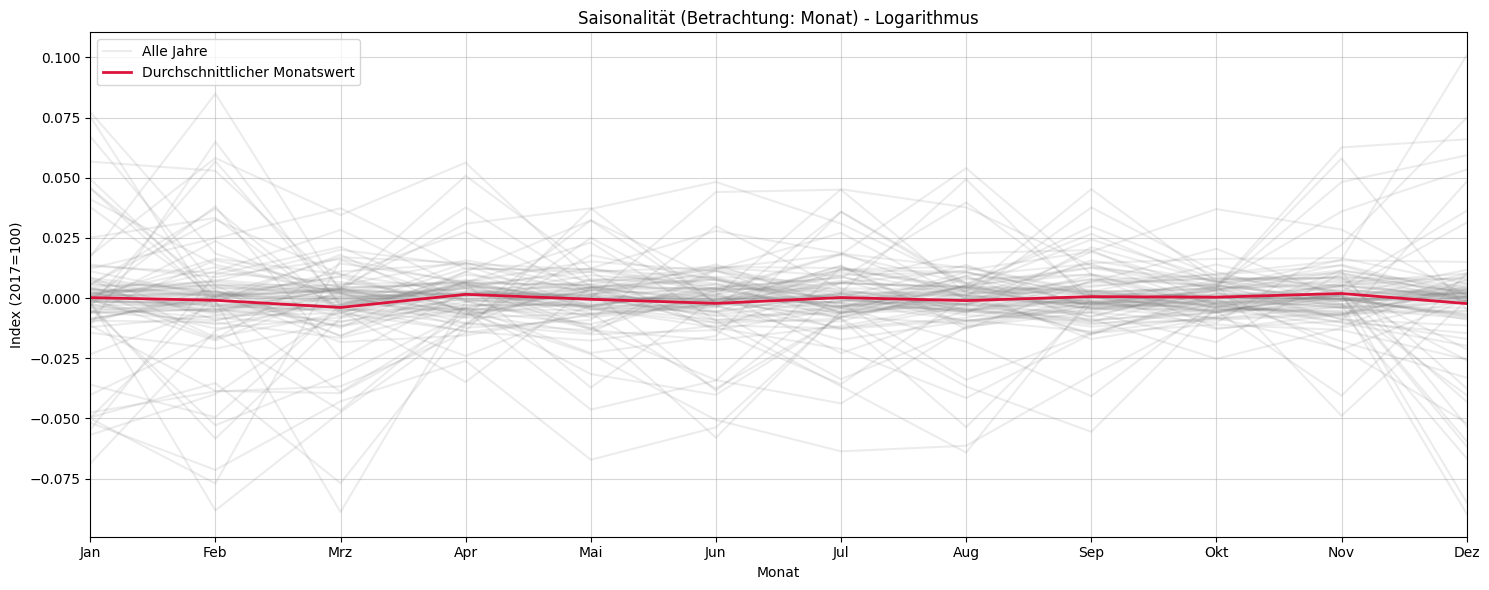

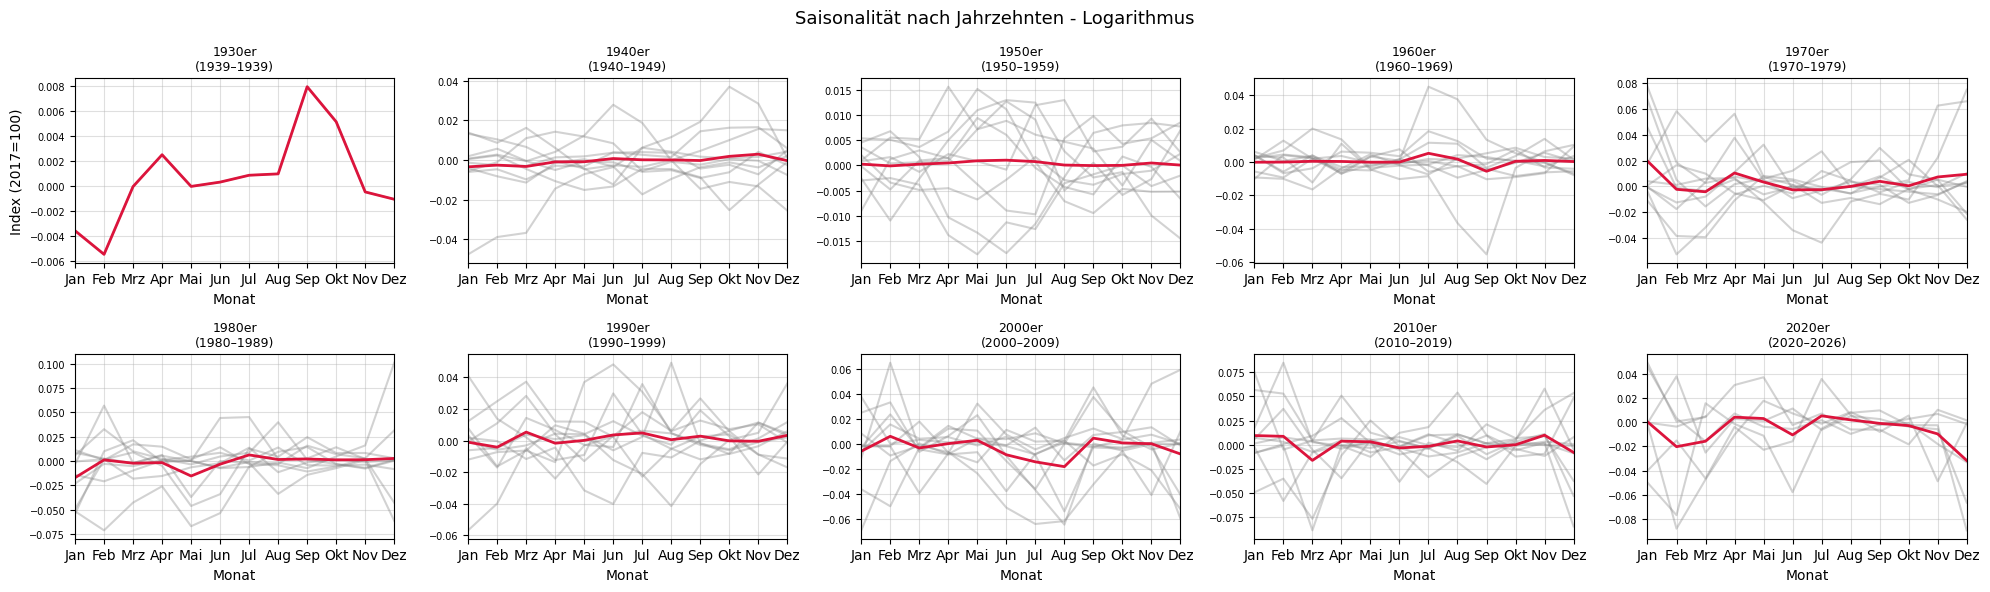

In [30]:
analyse_seasonality(df, col="log_residuum", title="Saisonalität (Betrachtung: Monat) - Logarithmus")
analyse_seasonality_by_decade(df, col="log_residuum", title="Saisonalität nach Jahrzehnten - Logarithmus")

<font color="orange">
Die Plots lassen erkennen, dass die Zeitreihe bereinigt ist. Die Saisonalitäten (Mittelwerte) liegen nahe bei 0, und das Residuum gleicht einem Rauschen.
</font>

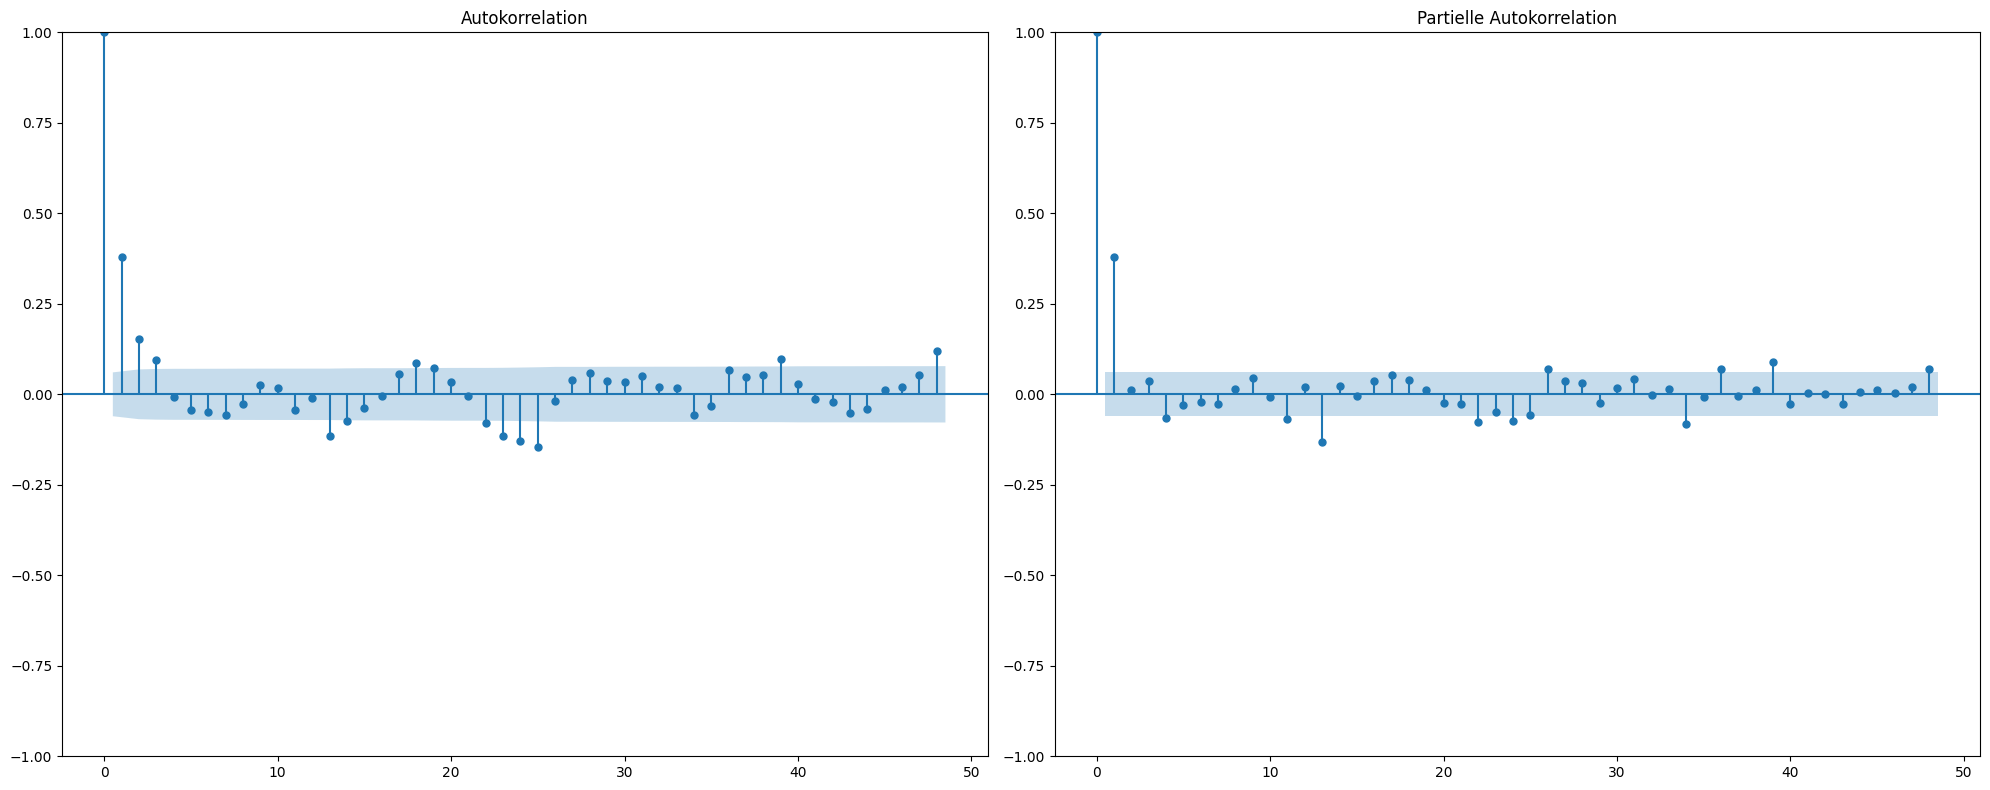

In [31]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Autokorrelation
_, ax = plt.subplots(1, 2, figsize=(20, 8))

plot_acf(df["log_residuum"], lags=48, ax=ax[0])
ax[0].set_title("Autokorrelation")

plot_pacf(df["log_residuum"], lags=48, ax=ax[1])
ax[1].set_title("Partielle Autokorrelation")

plt.tight_layout()
plt.show()

<font color="orange">
Die Autokorrelation-Werte schwanken relativ gleichmäßig um 0 herum, was darauf hindeutet, dass die Zeitreihe annähernd stationär ist.
</font>

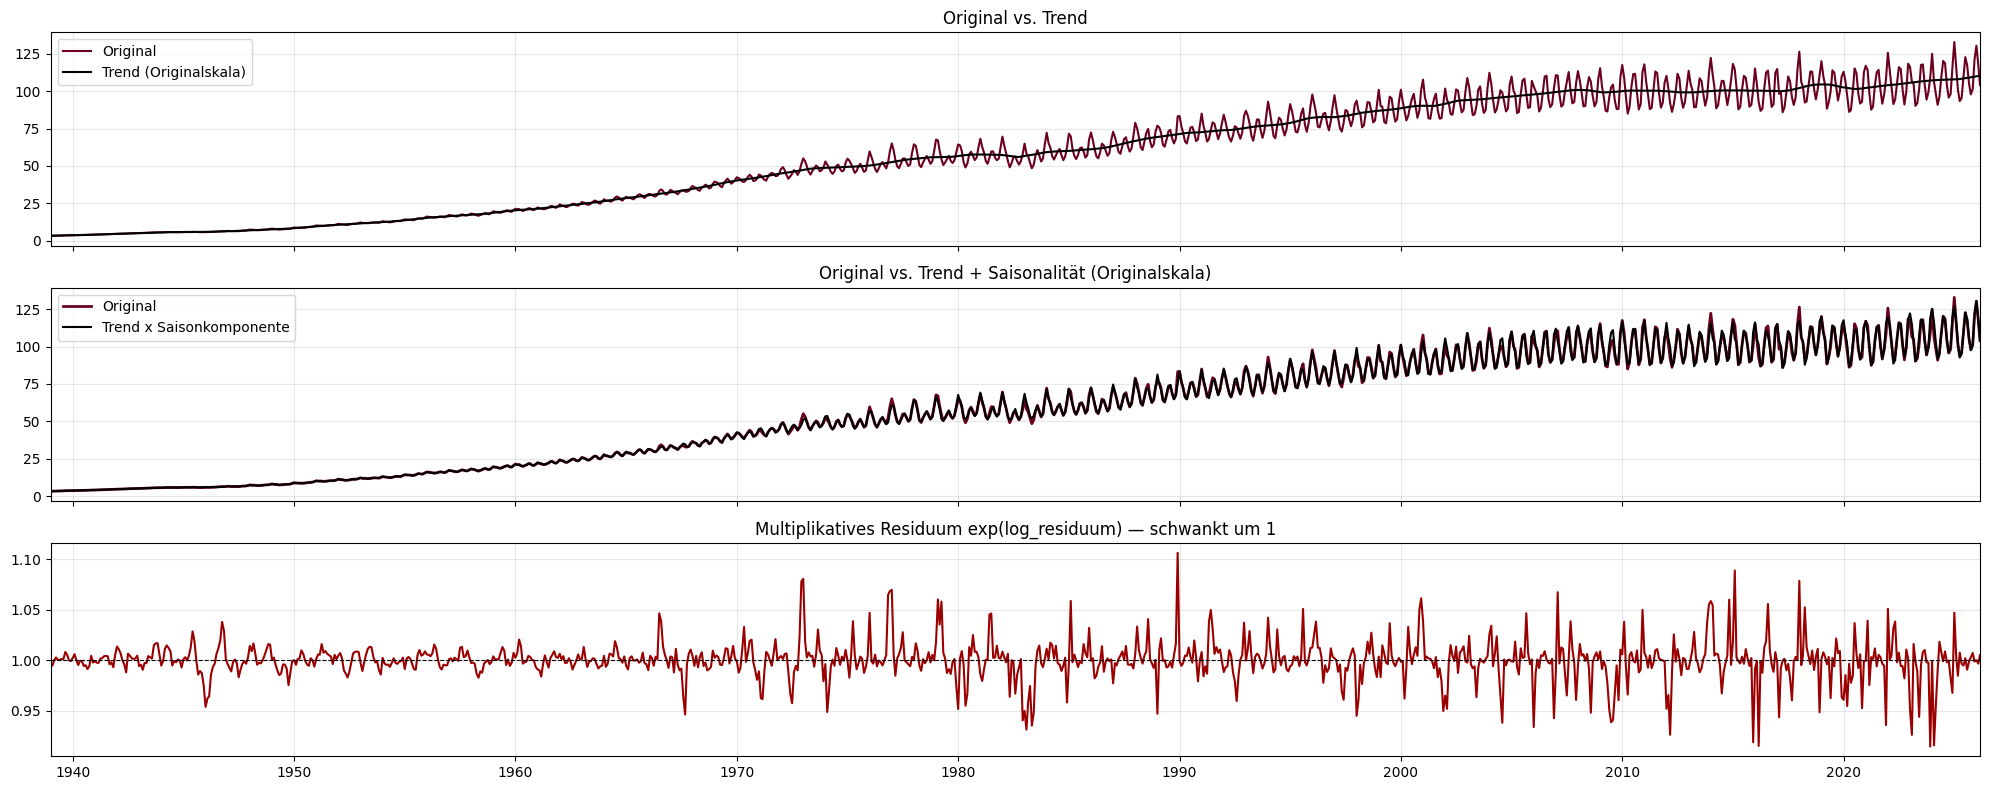

In [32]:
# Rücktransformation in Originalskala
df["trend_orig"] = np.exp(df["log_trend"])
df["saison_factor"] = np.exp(df["log_saison"])  # multiplikativer Saisonfaktor
df["resid_factor"] = np.exp(df["log_residuum"])  # multiplikativer Restfaktor, ≈ 1
df["reconstruction"] = df["trend_orig"] * df["saison_factor"]  # Trend x Saison, ohne Residuum

fig, axes = plt.subplots(3, 1, figsize=(20, 8), sharex=True)

axes[0].plot(df["value"], color="#6B001E", label="Original")
axes[0].plot(df["trend_orig"], color="black", label="Trend (Originalskala)")
axes[0].set_title("Original vs. Trend")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[0].margins(x=0)

axes[1].plot(df["value"], color="#6B001E", linewidth=2, label="Original")
axes[1].plot(df["reconstruction"], color="black", label="Trend x Saisonkomponente")
axes[1].set_title("Original vs. Trend + Saisonalität (Originalskala)")
axes[1].legend()
axes[1].grid(alpha=0.3)
axes[1].margins(x=0)

axes[2].plot(df["resid_factor"], color="#9B0000")
axes[2].axhline(1.0, color="black", linewidth=0.8, linestyle="--")
axes[2].set_title("Multiplikatives Residuum exp(log_residuum) — schwankt um 1")
axes[2].grid(alpha=0.3)
axes[2].margins(x=0)

plt.tight_layout()
plt.show()

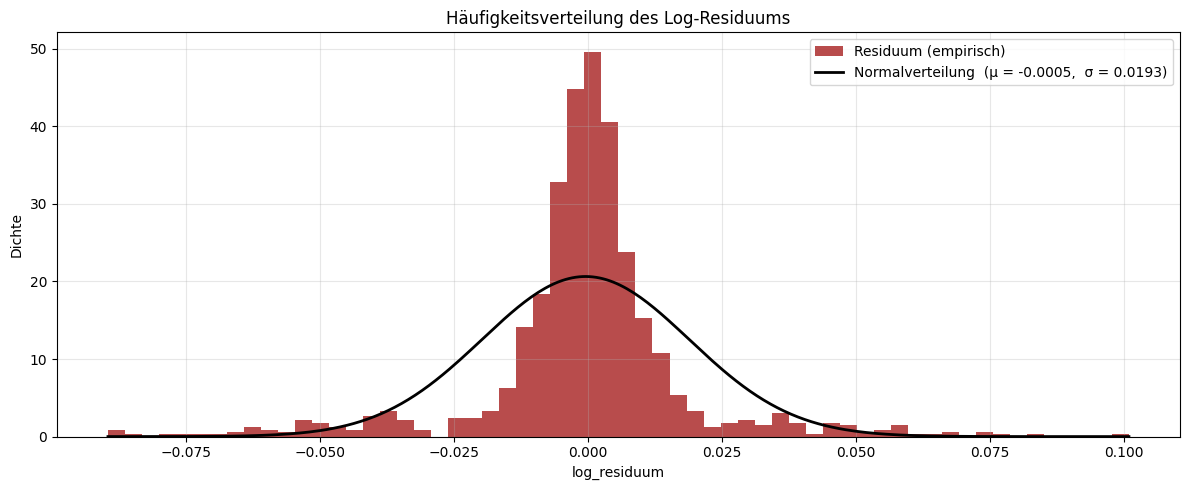

Mittelwert:          -0.000491
Standardabweichung:  0.019333
Schiefe:             -0.2715
Kurtosis:            5.4391   (Normalverteilung = 0)


In [36]:
from scipy import stats

residuum = df["log_residuum"].dropna()
mu, std = stats.norm.fit(residuum)

fig, ax = plt.subplots(figsize=(12, 5))

ax.hist(residuum, bins=60, density=True, color="#9B0000", alpha=0.7, label="Residuum (empirisch)")

x = np.linspace(residuum.min(), residuum.max(), 300)
ax.plot(
    x, stats.norm.pdf(x, mu, std), color="black", linewidth=2, label=f"Normalverteilung  (μ = {mu:.4f},  σ = {std:.4f})"
)

ax.set_title("Häufigkeitsverteilung des Log-Residuums")
ax.set_xlabel("log_residuum")
ax.set_ylabel("Dichte")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Mittelwert:          {mu:.6f}")
print(f"Standardabweichung:  {std:.6f}")
print(f"Schiefe:             {residuum.skew():.4f}")
print(f"Kurtosis:            {residuum.kurtosis():.4f}   (Normalverteilung = 0)")

<font color="orange">
Die Werte des Residuums sind normalverteilt, daher eignet sich die Zeitreihe für ARIMA. Es gibt einige extreme Ausreißer, siehe Kurtosis.
</font>

MSE:          0.0003197827403120209
RMSE:         0.017882470196033347
MAE:          0.011119346992386007
R2:           0.14444453754744158
AIC:          -5444.708253692385
BIC:          -5419.939832638032


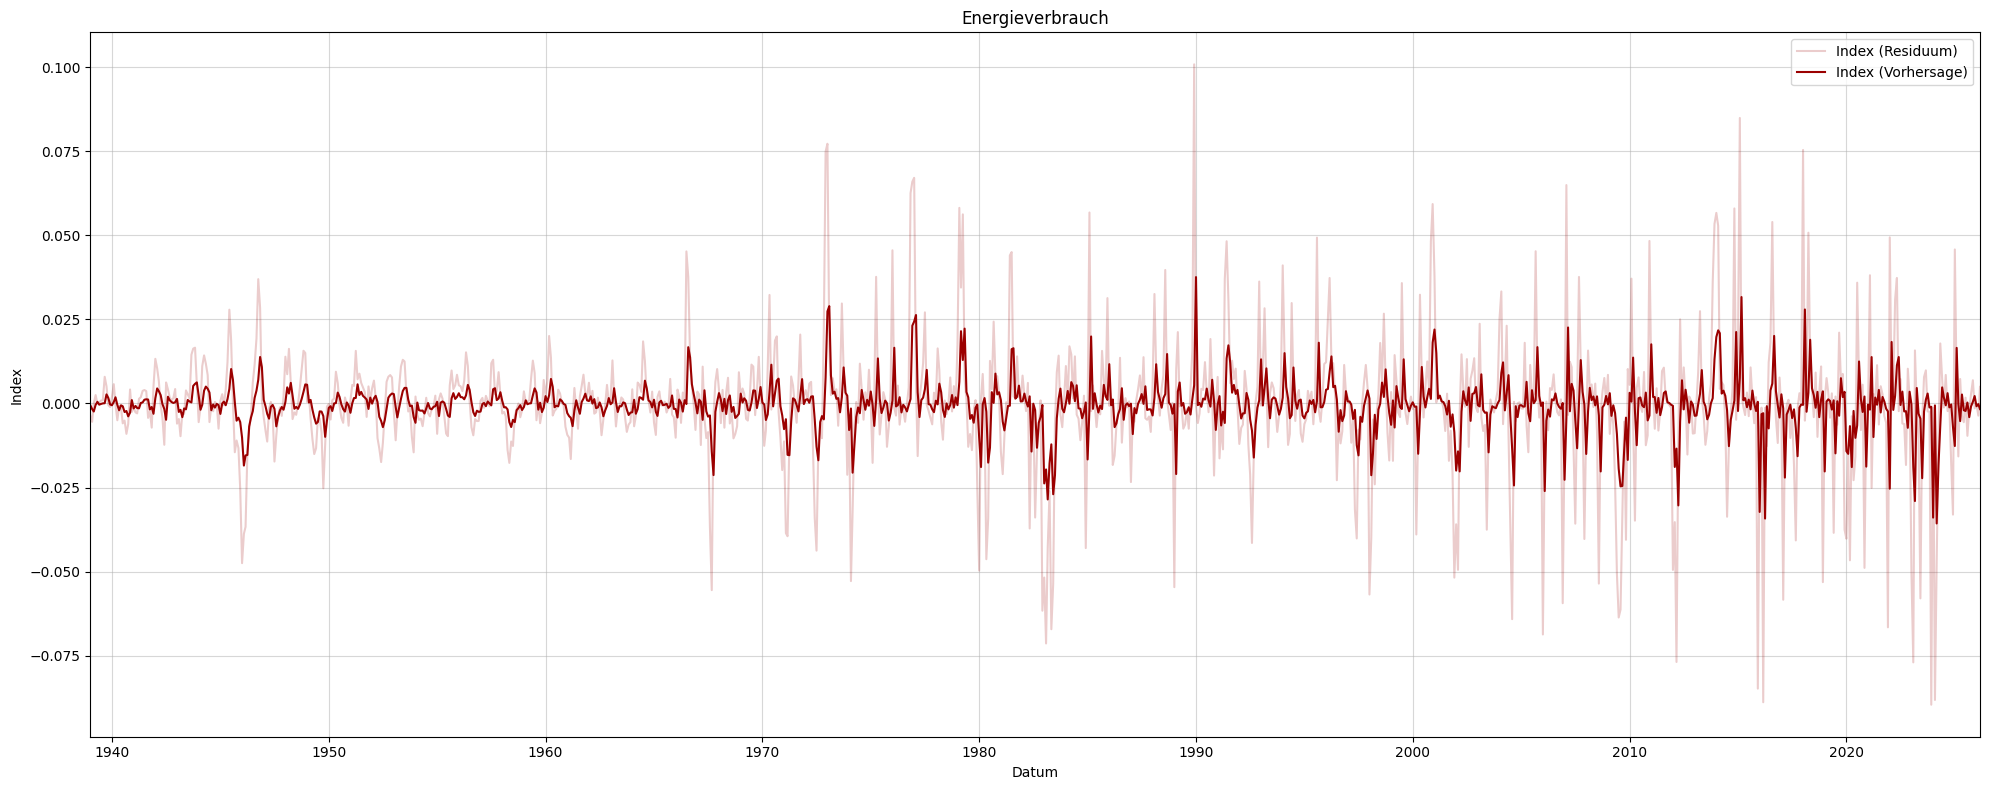

In [49]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error
from statsmodels.tsa.arima.model import ARIMA

time_series = df["log_residuum"].dropna()

model = ARIMA(time_series, order=(1, 0, 2), freq="MS")
model_fit = model.fit()

# print(model_fit.summary())

# Vorhersage
pred = model_fit.predict()

# Metriken
# Hier zu betrachten: MSE
print("MSE:         ", mean_squared_error(time_series, pred))
print("RMSE:        ", root_mean_squared_error(time_series, pred))
print("MAE:         ", mean_absolute_error(time_series, pred))
print("R2:          ", r2_score(time_series, pred))
print("AIC:         ", model_fit.aic)
print("BIC:         ", model_fit.bic)

# Darstellung
plt.figure(figsize=(20, 8))

plt.plot(df.index, df["log_residuum"], color="#9B0000", alpha=0.2, label="Index (Residuum)")
plt.plot(df.index, pred, color="#9B0000", label="Index (Vorhersage)")

plt.title("Energieverbrauch")
plt.xlabel("Datum")
plt.ylabel("Index")
plt.grid(alpha=0.5)
plt.margins(x=0)
plt.legend()
plt.tight_layout()
plt.show()

<font color="orange">
AR: Hier haben wir 1 gewählt, da in der PACF der Lag 1 signifikant ist, und die weiteren nicht.

Differencing: Da wir Saisonalität rausgerechnet haben, benötigen wir keine Differenzierung, daher 0.

MA: Hier sind bei der ACF die Lags 1 und 2 signifikant, daher wird für MA 2 gewählt.
</font>

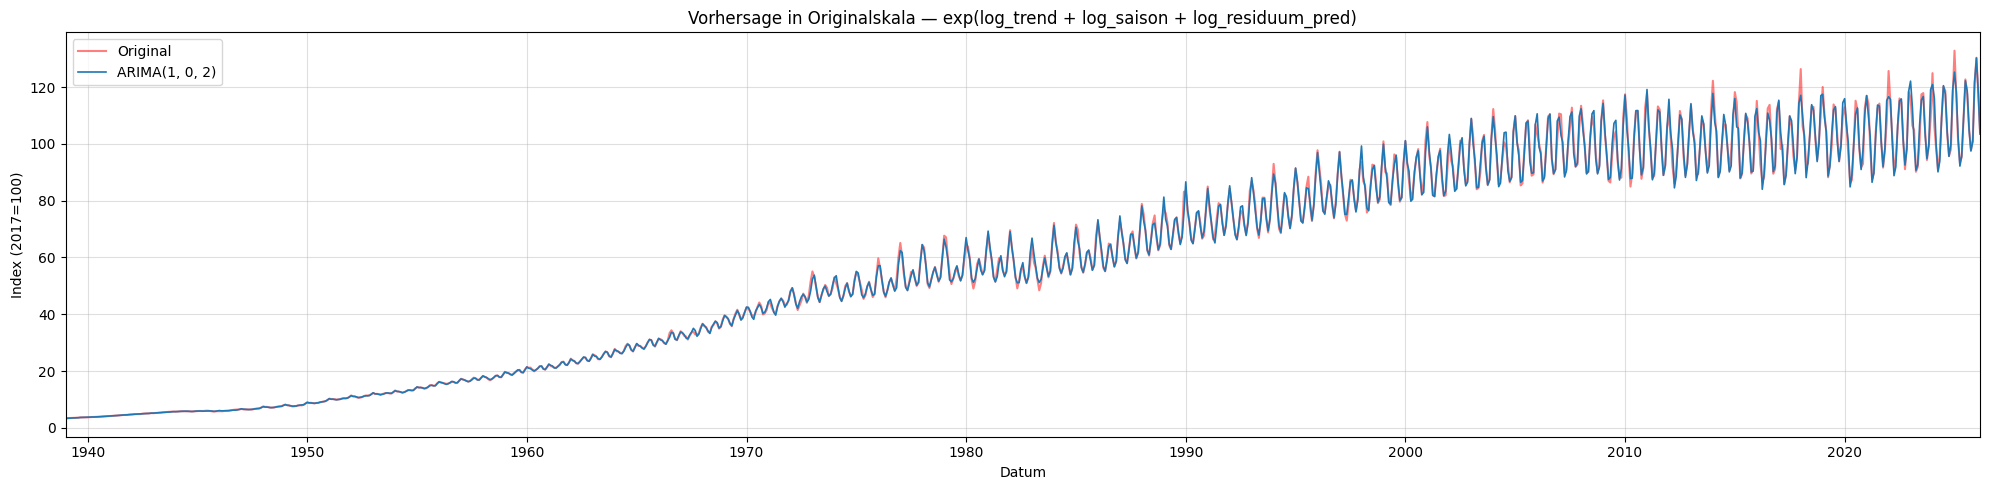

MSE:          2.552939052670058
RMSE:         1.5977919303432653
MAE:          0.812863597343816
R2:           0.998068228879665
AIC:          -5444.708253692385
BIC:          -5419.939832638032


In [ ]:
df_plot = df.dropna(subset=["log_trend", "log_saison", "log_residuum"]).copy()

# Rücktransformation jeder Modellvorhersage in den Originalraum

df_plot[f"pred_orig_{(1, 0, 2)}"] = np.exp(df_plot["log_trend"] + df_plot["log_saison"] + pred)

colors = {(1, 0, 0): "blue", (1, 0, 1): "green", (1, 0, 2): "orange"}

# plot 1

# --- Plot 2: Originalskala (Rücktransformation) ---
fig, ax = plt.subplots(figsize=(20, 5))
ax.plot(df_plot.index, df_plot["value"], color="red", alpha=0.5, label="Original")
ax.plot(df_plot.index, df_plot[f"pred_orig_{(1, 0, 2)}"], linewidth=1.2, label=f"ARIMA{(1, 0, 2)}")
ax.set_title("Vorhersage in Originalskala — exp(log_trend + log_saison + log_residuum_pred)")
ax.set_xlabel("Datum")
ax.set_ylabel("Index (2017=100)")
ax.legend()
ax.grid(alpha=0.4)
ax.margins(x=0)
plt.tight_layout()
plt.show()

# Metriken
print("MSE:         ", mean_squared_error(df["value"], df_plot[f"pred_orig_{(1, 0, 2)}"]))
print("RMSE:        ", root_mean_squared_error(df["value"], df_plot[f"pred_orig_{(1, 0, 2)}"]))
print("MAE:         ", mean_absolute_error(df["value"], df_plot[f"pred_orig_{(1, 0, 2)}"]))
print("R2:          ", r2_score(df["value"], df_plot[f"pred_orig_{(1, 0, 2)}"]))
print("AIC:         ", model_fit.aic)
print("BIC:         ", model_fit.bic)

<font color="orange">
Die Extremwerte (Varianz) werden auf den ersten Blick zwar nicht getroffen, bedenkt man jedoch die Skala um die es sich hier handelt, sind die vorhergesagten Werte sehr nach dran.

Transformiert man die Zeitreihe zur Originalskala, sind die relativen Abweichungen geringer. Die ausgegebene Evaluations-Metriken bestätigen dies.
</font>